## COMP661 Assignment 3 Canterbury Temperature forecasting 1174130 Ken Livingston

**Part 2: RNN-Based Temperature Forecasting**

We'll use the Canterbury Aero data as the basis for this notebook, firstly because it has the most complete record of data and secondly it correlates best with all the other weather stations.

In [1]:
# Import the libraries
import joblib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
import time
import torch
import torch.nn as nn

from IPython.display import Markdown, display
from pathlib import Path

In [4]:
# Set up the common parameters
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

# Relative paths
PROJECT_ROOT = Path("..", "..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PART1_MODEL_DIR = PROJECT_ROOT / "Part_1" / "models"
FIG_DIR = Path("..", "figures")
MODEL_DIR = Path("..", "models")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RERUN_EXPERIMENTS = False     # set to True to retrain all 36 experiment runs (if we want to run it with different data)

# Map station names to numbers
STATION_INFO = {
    "Christchurch Aero": {"id": "4843",  "folder": "christchurch_aero"},
    "Chch Kyle Street":  {"id": "24120", "folder": "christchurch_kyle_st_ews"},
    "Ashburton Aero":    {"id": "26170", "folder": "ashburton_aero_aws"},
    "Rangiora":          {"id": "17244", "folder": "rangiora_ews"},
    "Hanmer Forest":     {"id": "11234", "folder": "hanmer_forest_ews"},
}
STATIONS = list(STATION_INFO)
SOURCE_STATION = "Christchurch Aero"

FEATURES = ["evap_penman_ow", "evap_penman_pet", "evap_pt_pet",
            "max_temp", "min_temp", "mean_temp", "wind_speed", "rainfall"]
TARGET = "mean_temp"
TARGET_IDX = FEATURES.index(TARGET)
HORIZON = 7  #...days ahead

# Other settings, tweak some of these if necessary
WINDOW_LENGTHS = [7, 14, 30, 60]
CELL_TYPES = ["RNN", "LSTM", "GRU"]
SEEDS = [0, 1, 2]
HIDDEN_SIZE, NUM_LAYERS, DROPOUT = 64, 2, 0.2
BATCH_SIZE, LEARNING_RATE = 64, 1e-3
MAX_EPOCHS, PATIENCE = 100, 10

torch.set_num_threads(max(1, torch.get_num_threads()))
DEVICE = torch.device("cpu")

def set_seed(seed):     # Set the random seed for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def column_decimals(column, max_decimals=3):    # Round column decimals - might make things readable
    values = column.dropna().abs()
    for decimals in range(max_decimals + 1):
        if np.allclose(values, values.round(decimals)):
            return decimals
    return max_decimals

def show_table(table, title, max_decimals=3):
    display(Markdown(f"**{title}**"))
    float_columns = table.select_dtypes("float").columns
    number_formats = {col: f"{{:.{column_decimals(table[col], max_decimals)}f}}" for col in float_columns}
    display(table.style.format(number_formats))

print(f"PyTorch {torch.__version__}, running on {DEVICE} with {torch.get_num_threads()} threads")

PyTorch 2.14.1+cu130, running on cpu with 12 threads


We'll see how it goes with the CPU, if it proves to take too long we'll switch to Kaggle.

**Update:**  Everything ran well on the CPU - the longest run was about 16 minutes.

## 2.1 Individual RNN model

**Load the cleaned data, the split dates and the scaler from Part 1**
The cleaned daily data for all five stations is loaded from `data/processed/`. The chronological Train/Validation/Test dates and the feature scaler fitted on Christchurch Aero's training period are loaded from `Part_1/models/`, so this part uses the same split and scaling as Part 1.

In [ ]:
station_data = {}
for station, info in STATION_INFO.items():
    df = pd.read_csv(PROCESSED_DIR / f"{info['folder']}_daily_clean.csv", parse_dates=["date"])
    station_data[station] = df.set_index("date")[FEATURES]

split_dates = {name: [pd.Timestamp(d) for d in dates]
               for name, dates in json.loads((PART1_MODEL_DIR / "split_dates.json").read_text()).items()}
source_scaler = joblib.load(PART1_MODEL_DIR / "feature_scalers.joblib")[SOURCE_STATION]

split_table = pd.DataFrame({name: {"first day": d[0].date(), "last day": d[1].date(),
                                   "days": (d[1] - d[0]).days + 1} for name, d in split_dates.items()}).T
show_table(split_table, "Table 2.1 Chronological data split (identical for all stations)")
show_table(pd.DataFrame({"training mean": source_scaler.mean_, "training std": source_scaler.scale_},
                        index=[f"{f}" for f in FEATURES]).round(3),
           f"Table 2.2 Values for scaling, fitted on {SOURCE_STATION}'s training period (units: mm, degrees C, m/s)")

**Table 2.1 – Chronological data split (identical for all stations)**

,first day,last day,days
train,2006-03-01,2019-11-14,5007
validation,2019-11-15,2022-10-22,1073
test,2022-10-23,2025-09-30,1074


**Table 2.2 – Scaler fitted on Christchurch Aero's training period (units: mm, °C, m/s as per feature)**

,training mean,training std
evap_penman_ow,2.881,2.220
evap_penman_pet,2.566,1.984
evap_pt_pet,1.860,1.786
max_temp,17.046,5.613
min_temp,6.240,5.158
mean_temp,11.668,4.933
wind_speed,3.933,1.579
rainfall,1.800,5.238


All the stations will use the scaler that has been fitted to the Christchurch Aero data, which might show up their variations from the Christchurch Aero mean values.

We'll set up different sliding window lengths, to see how the forecasting goes.

In [6]:
def make_windows(scaled_values, dates, window, split_name):
    """Build (X, y, forecast_dates) for one split.
    X: [samples, window, 8 features], y: [samples, 7 days], forecast_dates: date of the first target day (t+1)."""
    first_day, last_day = split_dates[split_name]
    X, y, target_start = [], [], []
    for t in range(window - 1, len(dates) - HORIZON):          # t = forecast origin (last input day)
        if dates[t + 1] < first_day or dates[t + HORIZON] > last_day:
            continue
        X.append(scaled_values[t - window + 1: t + 1])
        y.append(scaled_values[t + 1: t + 1 + HORIZON, TARGET_IDX])
        target_start.append(dates[t + 1])
    return (torch.tensor(np.array(X), dtype=torch.float32),
            torch.tensor(np.array(y), dtype=torch.float32),
            pd.DatetimeIndex(target_start))

def scale_station(station):     # Scale each station according to the Christchurch Aero scaler
    return source_scaler.transform(station_data[station][FEATURES]), station_data[station].index

source_scaled, source_dates = scale_station(SOURCE_STATION)
sample_counts = {}
for window in WINDOW_LENGTHS:
    sample_counts[window] = {split: len(make_windows(source_scaled, source_dates, window, split)[0])
                             for split in ["train", "validation", "test"]}
X_example, y_example, _ = make_windows(source_scaled, source_dates, 30, "train")
print("Example shapes for a 30-day window → X:", tuple(X_example.shape), " y:", tuple(y_example.shape))
show_table(pd.DataFrame(sample_counts).T.rename_axis("window (days)"),
           f"Table 2.3  Number of samples per split at {SOURCE_STATION}, by input-window length")

Example shapes for a 30-day window → X: (4971, 30, 8)  y: (4971, 7)


**Table 2.3  Number of samples per split at Christchurch Aero, by input-window length**

,train,validation,test
window (days),,,
7,4994,1067,1068
14,4987,1067,1068
30,4971,1067,1068
60,4941,1067,1068


Longer windows lose a few records for training at the start and end of the date range, but is still well-enough covered that it's very unlikely to lead to any inaccuracy.

In [7]:
class TemperatureForecaster(nn.Module):     # Use a recurrent encoder (RNN, LSTM or GRU) with a linear head to produce a 7-day forecast

    def __init__(self, cell_type, n_features=len(FEATURES), hidden_size=HIDDEN_SIZE,
                 num_layers=NUM_LAYERS, dropout=DROPOUT, horizon=HORIZON):
        super().__init__()
        recurrent_class = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell_type]
        self.recurrent = recurrent_class(n_features, hidden_size, num_layers=num_layers,
                                         dropout=dropout, batch_first=True)
        self.head = nn.Linear(hidden_size, horizon)

    def forward(self, x):
        sequence_output, _ = self.recurrent(x)      # [batch, window, hidden]
        return self.head(sequence_output[:, -1])    # hidden state of the last day [batch, 7]


parameter_counts = {cell: sum(p.numel() for p in TemperatureForecaster(cell).parameters()) for cell in CELL_TYPES}
show_table(pd.DataFrame({"trainable parameters": parameter_counts}),
           "Table 2.4 Model size by recurrent cell type (64 hidden units, 2 layers)")

**Table 2.4 Model size by recurrent cell type (64 hidden units, 2 layers)**

,trainable parameters
RNN,13511
LSTM,52679
GRU,39623


We'll set up the model and give it a trial run to see how it goes for time.

Key parameters are:
* Loss: mean squared error on the scaled temperature over all 7 forecast days.
* Optimiser: Adam (with a learning rate 0.001), mini-batches of 64 samples, training samples shuffled every epoch.
* Early stopping: Training stops when it has not improved for 10 epochs (to a maximum 100), and the weights from the best epoch are restored.
* Error in degrees C: RMS Error on the scaled target is converted back to degrees C by multiplying by the training standard deviation of mean temperature.

In [ ]:
TARGET_STD = source_scaler.scale_[TARGET_IDX]
TARGET_MEAN = source_scaler.mean_[TARGET_IDX]


def predict(model, X, batch_size=1024):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])


def train_model(cell_type, window, seed, verbose=False):  #Train one model, with early stopping
    set_seed(seed)
    X_train, y_train, _ = make_windows(source_scaled, source_dates, window, "train")
    X_val, y_val, _ = make_windows(source_scaled, source_dates, window, "validation")
    model = TemperatureForecaster(cell_type).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()
    generator = torch.Generator().manual_seed(seed)

    best_val, best_state, epochs_without_improvement, history = np.inf, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(X_train), generator=generator)
        train_loss_sum = 0.0
        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]
            optimiser.zero_grad()
            loss = loss_fn(model(X_train[batch]), y_train[batch])
            loss.backward()
            optimiser.step()
            train_loss_sum += loss.item() * len(batch)
        train_mse = train_loss_sum / len(X_train)
        val_mse = loss_fn(predict(model, X_val), y_val).item()
        history.append({"epoch": epoch, "train_rmse_C": np.sqrt(train_mse) * TARGET_STD,
                        "val_rmse_C": np.sqrt(val_mse) * TARGET_STD})
        if val_mse < best_val - 1e-6:
            best_val, epochs_without_improvement = val_mse, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


# Quick check - train one small model and time it
start_time = time.time()
check_model, check_history = train_model("GRU", 14, seed=0)
print(f"GRU, 14-day window: {len(check_history)} epochs in {time.time() - start_time:.0f} s, "
      f"best validation RMSE = {check_history['val_rmse_C'].min():.3f} degrees")

GRU, 14-day window: 15 epochs in 12 s, best validation RMSE = 3.142 °C


Early stopping seems to have kicked in reasonably quickly (after 15 epochs), which indicates that run time might be feasible for running on a CPU.

We'll try the full run with 3 different seeds to get a fuller set of results, then save the outcomes.  This will be on the Training and Validation data - the Test dataset is still held back for final comparisons.

In [9]:
RESULTS_FILE = MODEL_DIR / "experiment_results.csv"
RUN_DIR = MODEL_DIR / "experiment_runs"
RUN_DIR.mkdir(exist_ok=True)

def run_name(cell, window, seed):
    return f"{cell}_w{window}_s{seed}"

def validation_metrics(model, window):
    X_val, y_val, _ = make_windows(source_scaled, source_dates, window, "validation")
    errors_C = (predict(model, X_val) - y_val).numpy() * TARGET_STD
    return np.sqrt((errors_C ** 2).mean()), np.abs(errors_C).mean()

if RERUN_EXPERIMENTS or not RESULTS_FILE.exists():
    rows, histories = [], {}
    experiment_start = time.time()
    for cell in CELL_TYPES:
        for window in WINDOW_LENGTHS:
            for seed in SEEDS:
                run_start = time.time()
                model, history = train_model(cell, window, seed)
                val_rmse, val_mae = validation_metrics(model, window)
                best_epoch = int(history.loc[history["val_rmse_C"].idxmin(), "epoch"])
                rows.append({"cell": cell, "window": window, "seed": seed, "best_epoch": best_epoch,
                             "epochs_run": len(history), "val_RMSE_C": val_rmse, "val_MAE_C": val_mae,
                             "train_RMSE_C_at_best": history.loc[best_epoch - 1, "train_rmse_C"],
                             "seconds": time.time() - run_start})
                torch.save(model.state_dict(), RUN_DIR / f"{run_name(cell, window, seed)}.pt")
                history.to_csv(RUN_DIR / f"{run_name(cell, window, seed)}_history.csv", index=False)
                print(f"{cell:<5} window={window:>2} seed={seed}: val RMSE {val_rmse:.3f} degrees C "
                      f"(best epoch {best_epoch}, {time.time() - run_start:.0f} s)")
    experiment_results = pd.DataFrame(rows)
    experiment_results.to_csv(RESULTS_FILE, index=False)
    print(f"\nAll 36 runs finished in {(time.time() - experiment_start) / 60:.1f} min")
else:
    experiment_results = pd.read_csv(RESULTS_FILE)
    print(f"Loaded saved results of {len(experiment_results)} runs from {RESULTS_FILE}")

summary = (experiment_results.groupby(["cell", "window"])
           .agg(val_RMSE_mean=("val_RMSE_C", "mean"), val_RMSE_std=("val_RMSE_C", "std"),
                val_MAE_mean=("val_MAE_C", "mean"), train_RMSE_mean=("train_RMSE_C_at_best", "mean"),
                best_epoch_mean=("best_epoch", "mean"), seconds_per_run=("seconds", "mean"))
           .reset_index())
summary["cell"] = pd.Categorical(summary["cell"], CELL_TYPES)
summary = summary.sort_values(["cell", "window"]).reset_index(drop=True)
show_table(summary.round(3).set_index(["cell", "window"]),
           "Table 2.5 Validation results by cell type and input window (degrees C; mean and std over 3 seeds)")

RNN   window= 7 seed=0: val RMSE 3.203 degrees C (best epoch 4, 4 s)
RNN   window= 7 seed=1: val RMSE 3.196 degrees C (best epoch 11, 8 s)
RNN   window= 7 seed=2: val RMSE 3.189 degrees C (best epoch 4, 8 s)
RNN   window=14 seed=0: val RMSE 3.148 degrees C (best epoch 20, 9 s)
RNN   window=14 seed=1: val RMSE 3.141 degrees C (best epoch 5, 13 s)
RNN   window=14 seed=2: val RMSE 3.150 degrees C (best epoch 4, 5 s)
RNN   window=30 seed=0: val RMSE 3.108 degrees C (best epoch 12, 19 s)
RNN   window=30 seed=1: val RMSE 3.116 degrees C (best epoch 15, 15 s)
RNN   window=30 seed=2: val RMSE 3.124 degrees C (best epoch 8, 9 s)
RNN   window=60 seed=0: val RMSE 3.124 degrees C (best epoch 5, 35 s)
RNN   window=60 seed=1: val RMSE 3.113 degrees C (best epoch 10, 23 s)
RNN   window=60 seed=2: val RMSE 3.137 degrees C (best epoch 4, 33 s)
LSTM  window= 7 seed=0: val RMSE 3.224 degrees C (best epoch 10, 7 s)
LSTM  window= 7 seed=1: val RMSE 3.225 degrees C (best epoch 9, 13 s)
LSTM  window= 7 seed=

**Table 2.5 Validation results by cell type and input window (degrees C; mean and std over 3 seeds)**

There is very little difference between the models. All trained quickly and finished early (at most taking 20 epochs).  GRU was the slowest to run, but still within an acceptable time, even with a window of 60).

The very small difference between training and validation RMS Error, and the low standard deviation indicate there was very little over-fitting. 

The main differentiator is the size of the window, with 30 and 60 giving the best results, by a very small margin.  This points to a month's worth of data being useful for prediction that the most recent 7 days, which points back to the Part 1 finding that seasonal values are more useful than very recent readings.

How does that look?

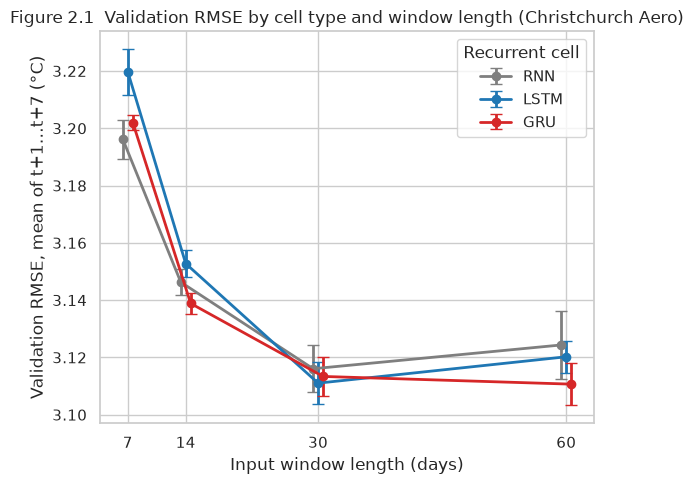

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
cell_colours = {"RNN": "#7f7f7f", "LSTM": "#1f77b4", "GRU": "#d62728"}
for offset, cell in zip([-0.6, 0, 0.6], CELL_TYPES):
    cell_rows = summary[summary["cell"] == cell]
    ax.errorbar(cell_rows["window"] + offset, cell_rows["val_RMSE_mean"], yerr=cell_rows["val_RMSE_std"],
                marker="o", capsize=4, lw=2, color=cell_colours[cell], label=cell)
ax.set_xticks(WINDOW_LENGTHS)
ax.set_xlabel("Input window length (days)")
ax.set_ylabel("Validation RMSE, mean of t+1…t+7 (°C)")
ax.set_title(f"Figure 2.1  Validation RMSE by cell type and window length ({SOURCE_STATION})")
ax.legend(title="Recurrent cell")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_validation_rmse_by_config.png", dpi=150)
plt.show()

This shows how close all the models were, and confirms that 60 days is a good-enough window, with minimal time saving by going with 30 days.  Looking at this plot, it seems GRU over 60 days gives a tiny bit more accuracy, but there's very little in it - all models are pretty good.  Let's confirm that with the numbers, and save the best configuration.

In [ ]:
best_config = summary.loc[summary["val_RMSE_mean"].idxmin()]
FINAL_CELL, FINAL_WINDOW = str(best_config["cell"]), int(best_config["window"])
config_runs = experiment_results[(experiment_results["cell"] == FINAL_CELL) &
                                 (experiment_results["window"] == FINAL_WINDOW)]
FINAL_SEED = int(config_runs.loc[config_runs["val_RMSE_C"].idxmin(), "seed"])

final_model = TemperatureForecaster(FINAL_CELL)
final_model.load_state_dict(torch.load(RUN_DIR / f"{run_name(FINAL_CELL, FINAL_WINDOW, FINAL_SEED)}.pt"))
final_model.eval()
final_history = pd.read_csv(RUN_DIR / f"{run_name(FINAL_CELL, FINAL_WINDOW, FINAL_SEED)}_history.csv")

# Save the final model and everything needed to re-use it later
torch.save(final_model.state_dict(), MODEL_DIR / "final_model.pt")
final_config = {"source_station": SOURCE_STATION, "cell_type": FINAL_CELL, "window_days": FINAL_WINDOW,
                "seed": FINAL_SEED, "hidden_size": HIDDEN_SIZE, "num_layers": NUM_LAYERS, "dropout": DROPOUT,
                "features": FEATURES, "target": TARGET, "horizon_days": HORIZON,
                "scaler": "Part_1/models/feature_scalers.joblib (Christchurch Aero, training period)",
                "validation_RMSE_C": float(config_runs["val_RMSE_C"].min())}
(MODEL_DIR / "final_model_config.json").write_text(json.dumps(final_config, indent=2))

ranking = summary.sort_values("val_RMSE_mean")[["cell", "window", "val_RMSE_mean", "val_RMSE_std"]].head(5)
show_table(ranking.round(3).reset_index(drop=True), "Table 2.6 Five best configurations by mean validation RMSE (degrees C)")
print(f"Final model: {FINAL_CELL}, {FINAL_WINDOW}-day window, seed {FINAL_SEED} "
      f"(validation RMSE {final_config['validation_RMSE_C']:.3f} degrees) → saved to {MODEL_DIR / 'final_model.pt'}")

**Table 2.6 Five best configurations by mean validation RMSE (degrees C)**

,cell,window,val_RMSE_mean,val_RMSE_std
0,GRU,60,3.111,0.007
1,LSTM,30,3.111,0.007
2,GRU,30,3.113,0.007
3,RNN,30,3.116,0.008
4,LSTM,60,3.120,0.006


Final model: GRU, 60-day window, seed 1 (validation RMSE 3.104 °C) → saved to ../models/final_model.pt


How does the training and validation progress look for that model?

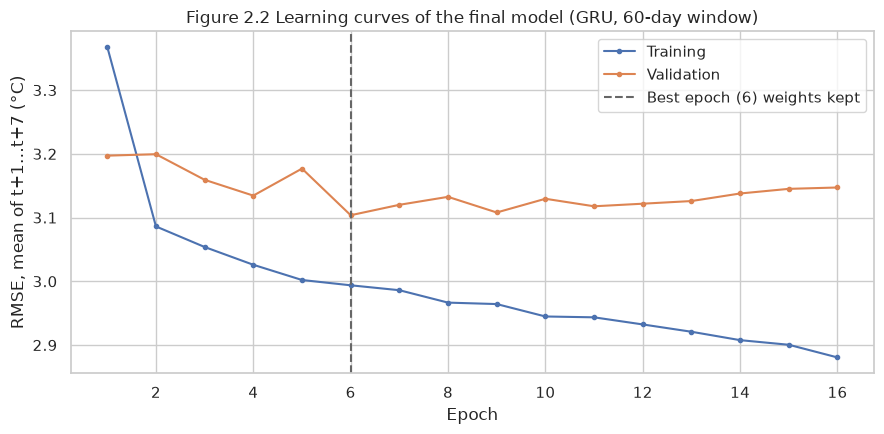

In [ ]:
best_epoch = int(final_history.loc[final_history["val_rmse_C"].idxmin(), "epoch"])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(final_history["epoch"], final_history["train_rmse_C"], marker=".", label="Training")
ax.plot(final_history["epoch"], final_history["val_rmse_C"], marker=".", label="Validation")
ax.axvline(best_epoch, color="0.4", ls="--", label=f"Best epoch ({best_epoch}) weights kept")
ax.set_xlabel("Epoch")
ax.set_ylabel("RMSE, mean of t+1…t+7 (degrees)")
ax.set_title(f"Figure 2.2 Learning curves of the final model ({FINAL_CELL}, {FINAL_WINDOW}-day window)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_final_model_learning_curves.png", dpi=150)
plt.show()

Training was still getting better at epoch 16, but it looks like it was starting to over-fit from epoch 6, where the RMS Error reached its lowest value.

**Baseline**
There are two possible baselines:
1.  Persistance - a continuation of today's temperature - what we get today is what we're going to get for the next 7 days.
2.  Climate/seasonal - the forecast is the long-term average for that day of the year, for that station, calculated from the training data only, and smoothed with a 31-day moving average.

Both of these baselines don't need any machine learning.  Part 1 found that climate/seasonal seemed to be a very good predictor, so we'll see how it stacks up here.

In [14]:
def climatology_lookup(station):    # Smoothed day-of-year mean temperature from the station's training period
    train_start, train_end = split_dates["train"]
    train_temp = station_data[station].loc[train_start:train_end, TARGET]
    by_day = train_temp.groupby(train_temp.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
    wrapped = pd.concat([by_day.iloc[-15:], by_day, by_day.iloc[:15]])          # wrap around new year
    return wrapped.rolling(31, center=True).mean().iloc[15:-15]

def evaluate_station(station, model=final_model, window=FINAL_WINDOW):
    scaled, dates = scale_station(station)
    X_test, y_test, target_start = make_windows(scaled, dates, window, "test")
    forecast_C = predict(model, X_test).numpy() * TARGET_STD + TARGET_MEAN
    observed_C = y_test.numpy() * TARGET_STD + TARGET_MEAN
    last_observed_C = X_test[:, -1, TARGET_IDX].numpy() * TARGET_STD + TARGET_MEAN
    persistence_C = np.repeat(last_observed_C[:, None], HORIZON, axis=1)
    climatology = climatology_lookup(station)
    target_days = np.array([target_start + pd.Timedelta(days=h) for h in range(HORIZON)]).T
    climatology_C = climatology.reindex(pd.DatetimeIndex(target_days.ravel()).dayofyear).to_numpy().reshape(target_days.shape)
    return {"dates": target_start, "forecast": forecast_C, "observed": observed_C,
            "persistence": persistence_C, "climatology": climatology_C}

def error_metrics(forecast, observed):
    errors = forecast - observed
    return {"MAE_C": np.abs(errors).mean(), "RMSE_C": np.sqrt((errors ** 2).mean()),
            "R2": 1 - (errors ** 2).sum() / ((observed - observed.mean()) ** 2).sum(),
            "bias_C": errors.mean()}

test_results = {station: evaluate_station(station) for station in STATIONS}
check = test_results[SOURCE_STATION]
print(f"{SOURCE_STATION} test forecasts: {check['forecast'].shape[0]} forecast origins × {HORIZON} days, "
      f"{check['dates'][0].date()} → {check['dates'][-1].date()}")
baseline_table = pd.DataFrame({name: error_metrics(check[name], check["observed"])
                               for name in ["forecast", "persistence", "climatology"]}).T
baseline_table.index = ["Final model", "Persistence", "Climatology"]
show_table(baseline_table.round(3), f"Table 2.7 Test-set errors at {SOURCE_STATION}, all 7 forecast days pooled")

Christchurch Aero test forecasts: 1068 forecast origins × 7 days, 2022-10-23 → 2025-09-24


**Table 2.7 Test-set errors at Christchurch Aero, all 7 forecast days pooled**

,MAE_C,RMSE_C,R2,bias_C
Final model,2.407,3.004,0.631,0.244
Persistence,3.186,4.060,0.326,-0.002
Climatology,2.476,3.068,0.615,-0.271


New Zealand's changeable weather shows clearly because persistance scores badly compared with the others.  The final model is just a tiny bit better at predicting temperature than climate/seasonal on all the measures.  The final model shows a bias of +0.244 degrees while climate/seasonal gives a bias of -0.271 degrees - both of which may be due to climate change (overall temperatures have gone up by a quarter of a degree or so in the ten years between the mean training data, around July 2014, and mean final test data, around May 2024).

We'll run that model for the other stations.  The expectation is that the seasonal effect will be the stronger, and with some bias depending on local conditions around each station.  To test that, we'll score for skill (the model) vs climatology: 1 − RMSE_model / RMSE_climatology. A value above 0 means the model beats the climatology baseline.

In [ ]:
comparison_rows = []
for station in STATIONS:
    result = test_results[station]
    pooled = error_metrics(result["forecast"], result["observed"])
    rmse_by_day = np.sqrt(((result["forecast"] - result["observed"]) ** 2).mean(axis=0))
    climatology_rmse = error_metrics(result["climatology"], result["observed"])["RMSE_C"]
    comparison_rows.append({
        "Station ID": STATION_INFO[station]["id"],
        "Station": station,
        "Role": "SOURCE (train + validation)" if station == SOURCE_STATION else "Test only (no retraining)",
        "MAE (°C)": pooled["MAE_C"], "RMSE (°C)": pooled["RMSE_C"], "R²": pooled["R2"],
        "Bias (°C)": pooled["bias_C"],
        "RMSE t+1 (°C)": rmse_by_day[0], "RMSE t+7 (°C)": rmse_by_day[-1],
        "Skill vs climatology": 1 - pooled["RMSE_C"] / climatology_rmse,
    })
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(MODEL_DIR / "test_comparison_table.csv", index=False)


def highlight_source(row):
    return ["font-weight: bold; background-color: #e8f0fe" if row["Station"] == SOURCE_STATION else "" for _ in row]

display(Markdown(f"Table 2.8 Test-set performance of the final model ({FINAL_CELL}, {FINAL_WINDOW}-day window) "
                 f"at each station, 2022-10-23 to 2025-09-30. The source station (highlighted) was used for "
                 f"training and validation; the other four were used only for testing."))
display(comparison_table.style.apply(highlight_source, axis=1)
        .format({c: "{:.3f}" for c in comparison_table.columns if c not in ["Station ID", "Station", "Role"]})
        .hide(axis="index"))

Table 2.8 Test-set performance of the final model (GRU, 60-day window) at each station, 23 Oct 2022 to 30 Sep 2025. The source station (highlighted) was used for training and validation; the other four were used only for testing.

Station ID,Station,Role,MAE (°C),RMSE (°C),R²,Bias (°C),RMSE t+1 (°C),RMSE t+7 (°C),Skill vs climatology
4843,Christchurch Aero,SOURCE (train + validation),2.407,3.004,0.631,0.244,2.622,3.089,0.021
24120,Chch Kyle Street,Test only (no retraining),2.242,2.853,0.661,-0.001,2.477,2.932,0.023
26170,Ashburton Aero,Test only (no retraining),2.529,3.140,0.576,0.307,2.758,3.220,0.013
17244,Rangiora,Test only (no retraining),2.377,2.965,0.598,0.618,2.696,2.998,-0.002
11234,Hanmer Forest,Test only (no retraining),3.020,3.715,0.548,1.306,3.184,3.757,-0.040


The Christchurch Aero-trained model worked best for Christchurch Kyle Street - probably because they are only 8km apart, and Kyle Street is in the middle of the city and will therefore get more stable temperatures.  The model is just 2% better than climate/seasonal for the Christchurch stations, 1% better for Ashburton, no better for Rangiora, but for Hanmer Forest it's worse (as expected) - Hanmer Forest would be better off just using climate/seasonal historic data for predicting temperatures instead of the Christchurch Aero model.

How does that look for each day of predictions?

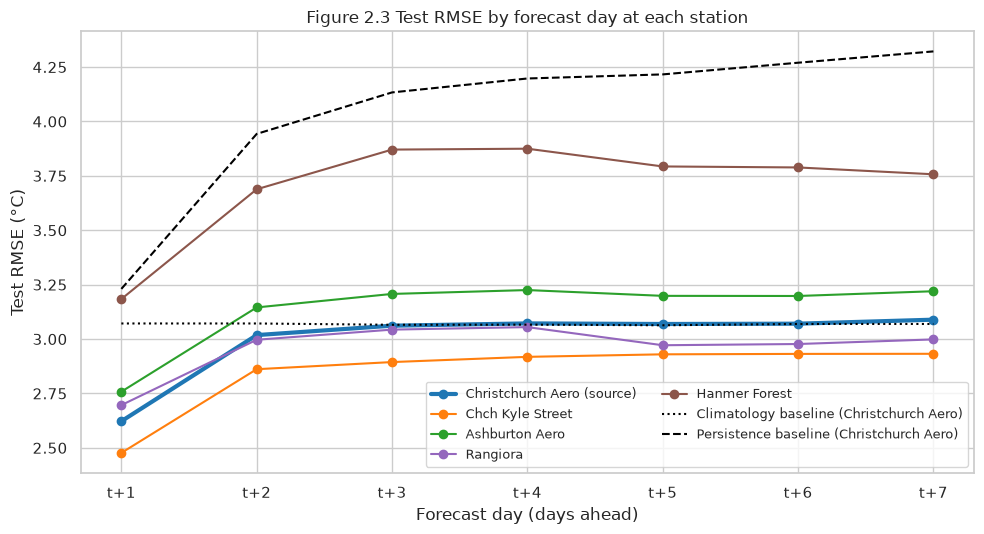

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))
station_colours = dict(zip(STATIONS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#8c564b"]))
lead_days = np.arange(1, HORIZON + 1)
for station in STATIONS:
    result = test_results[station]
    rmse_by_day = np.sqrt(((result["forecast"] - result["observed"]) ** 2).mean(axis=0))
    is_source = station == SOURCE_STATION
    ax.plot(lead_days, rmse_by_day, marker="o", lw=3 if is_source else 1.5, color=station_colours[station],
            label=f"{station} (source)" if is_source else station)
source_result = test_results[SOURCE_STATION]
for baseline, style in [("climatology", ":"), ("persistence", "--")]:
    baseline_rmse = np.sqrt(((source_result[baseline] - source_result["observed"]) ** 2).mean(axis=0))
    ax.plot(lead_days, baseline_rmse, ls=style, color="black", lw=1.5,
            label=f"{baseline.capitalize()} baseline ({SOURCE_STATION})")
ax.set_xticks(lead_days)
ax.set_xticklabels([f"t+{d}" for d in lead_days])
ax.set_xlabel("Forecast day (days ahead)")
ax.set_ylabel("Test RMSE (degrees)")
ax.set_title("Figure 2.3 Test RMSE by forecast day at each station")
ax.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_test_rmse_by_forecast_day.png", dpi=150)
plt.show()

The model is good for the first couple of days but then settles to where the climate/seasonal sits, which is consistent with the findings in Part 1.  Day to day variations from the seasonal long-term average are just over 3 degrees and the model doesn't do any better.  The persistence baseline (same temperature as today, forecast for the next 7 days) is consistently worse than the other methods.  The plots for the other four stations show a similar pattern as Christchurch Aero and are higher or lower for their cooler (Hanmer) or warmer (Kyle Street) locations, respectively.

How does the forecast versus actuals look, for each station, across a year?  We'll use a full year for 2024.

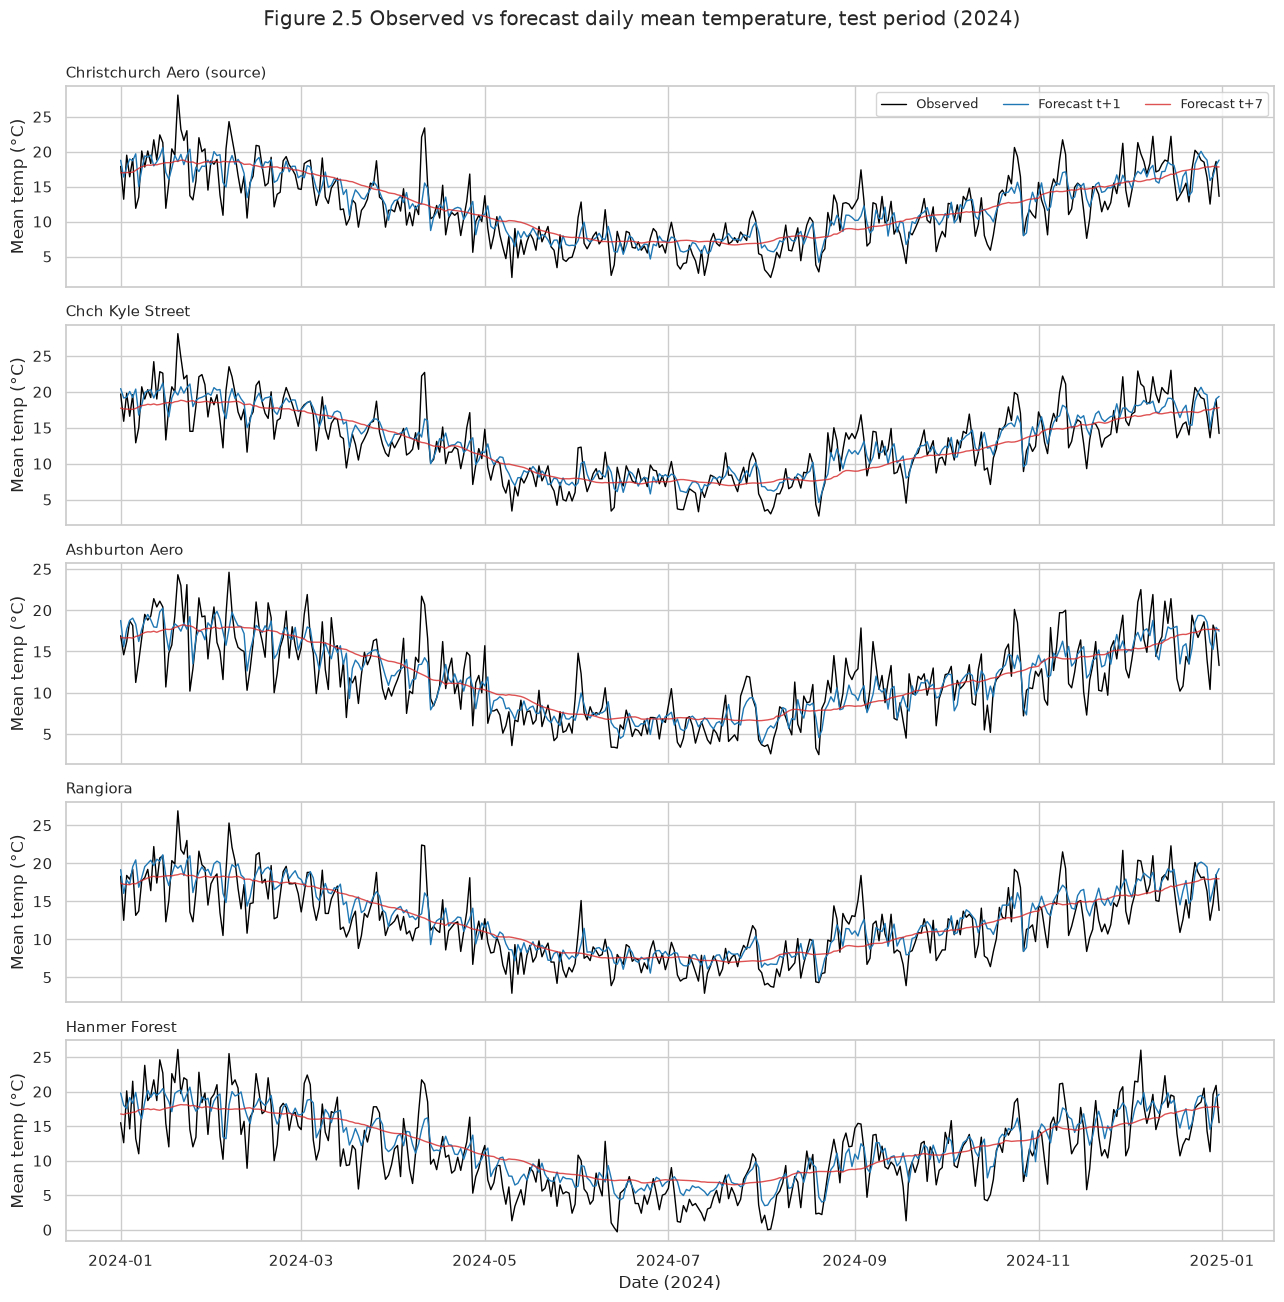

In [ ]:
plot_start, plot_end = pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31")
fig, axes = plt.subplots(len(STATIONS), 1, figsize=(13, 2.6 * len(STATIONS)), sharex=True)
for ax, station in zip(axes, STATIONS):
    result = test_results[station]
    dates = result["dates"]
    observed = pd.Series(result["observed"][:, 0], index=dates)
    day1 = pd.Series(result["forecast"][:, 0], index=dates)
    day7 = pd.Series(result["forecast"][:, -1], index=dates + pd.Timedelta(days=HORIZON - 1))
    ax.plot(observed[plot_start:plot_end], color="black", lw=1, label="Observed")
    ax.plot(day1[plot_start:plot_end], color="#1f77b4", lw=1, label="Forecast t+1")
    ax.plot(day7[plot_start:plot_end], color="#d62728", lw=1, alpha=0.8, label="Forecast t+7")
    ax.set_ylabel("Mean temp (°C)")
    ax.set_title(f"{station}{' (source)' if station == SOURCE_STATION else ''}", loc="left", fontsize=11)
axes[0].legend(ncol=3, loc="upper right", fontsize=9)
axes[-1].set_xlabel("Date")
fig.suptitle("Figure 2.4 Observed vs forecast daily mean temperature, test period (2024)", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_forecast_vs_observed_2024.png", dpi=150)
plt.show()

This illustrates the daily variability of weather in Canterbury - the forecasts are smoother, generally capturing the trend of the changes but not the extent - reality is spikier.

**Summary**

**Model development (Christchurch Aero, training and validation data only)**
* Christchurch Aero had the most complete dataset and was physically the most central station, which made it the obvious choice as the source station.
* We tried 12 configurations (simple RNN, LSTM, GRU with input windows of 7, 14, 30, 60 days), each trained with 3 seeds, using early stopping on the validation set.
* **Input-window length was the most significant choice:** 30–60-day windows reduced validation RMSE from around 3.20 °C (7 days) to around 3.11 °C. The longer histories let the model place itself in the seasonal cycle.
* **Cell type barely mattered:** at 30–60 days the RNN, LSTM and GRU differed by less than 0.01 °C, about the size of the random-seed variation.  60 days had the tiniest advantage, so we went with that.
* **Final model:** GRU, 60-day window, 2 layers × 64 units (which gave a validation RMSE of 3.10 degrees C).

**Test results (2022-10-23 to 2025-9-30, same frozen model at every station)**
Running the model on the held-back test data pointed to the following conclusions:
* At Christchurch Aero: RMSE 3.00 degrees, MAE 2.41 degrees, R2 0.63. This was much better than persistence (4.06 degrees) and very slightly better than climatology (3.07 degrees).
* The model's real advantage is at 1–2 days ahead (t+1 RMSE 2.5–2.8 degrees at the Canterbury Plains stations, which is about 15 % better than climatology). From t+3 onward it effectively forecasts the climate/seasonal average. This is consistent with Part 1's finding that day-to-day weather signal fades within about three days.
* The forecasts were conservative - they consistently showed lower highs and higher lows that reality, but that highlights the variability of daily weather in Canterbury.
* **Transfer to other stations** works well where the climate is similar: Chch Kyle Street (RMSE 2.85 degrees) and Rangiora (2.97 degrees) are as good as or better than the source, and Ashburton Aero is close (3.14 degrees).  It didn't work so well for Hanmer Forest (RMSE of 3.72 degrees), mostly because it has colder winters and fractionally cooler summers, so Hanmer's own climatology was better.
* Weather is regional, and for the Canterbury Plains weather stations one station could be used reasonably effectively as a proxy for the others, subject to a small shift to allow for the local long-term average.  (At least for temperature.)